# Heart Disease UCI - EDA

In this notebook I explore the cleaned dataset (`data/heart_clean.csv`, made by `data/download_data.py`).

Target: `0` = no heart disease, `1` = heart disease.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/heart_clean.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0


In [2]:
print(df.shape)
df.info()

(303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


## Missing values
The raw data had 4 missing `ca` and 2 missing `thal` values. They were filled with the mode in the download script, so now there should be none.

In [3]:
raw = pd.read_csv('../data/heart_raw.csv')
print('raw missing:\n', raw.isnull().sum()[raw.isnull().sum() > 0])
print('clean missing total:', df.isnull().sum().sum())

raw missing:
 ca      4
thal    2
dtype: int64
clean missing total: 0


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Class balance
Classes are fairly balanced (164 vs 139) so I don't need oversampling. Accuracy is ok as a metric but I also check ROC-AUC, precision and recall.

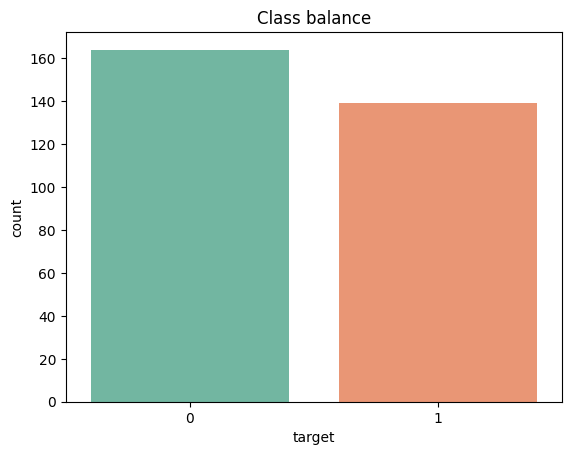

target
0    0.541254
1    0.458746
Name: proportion, dtype: float64

In [5]:
sns.countplot(x='target', data=df, hue='target', palette='Set2', legend=False)
plt.title('Class balance')
plt.show()
df['target'].value_counts(normalize=True)

## Histograms of numeric features

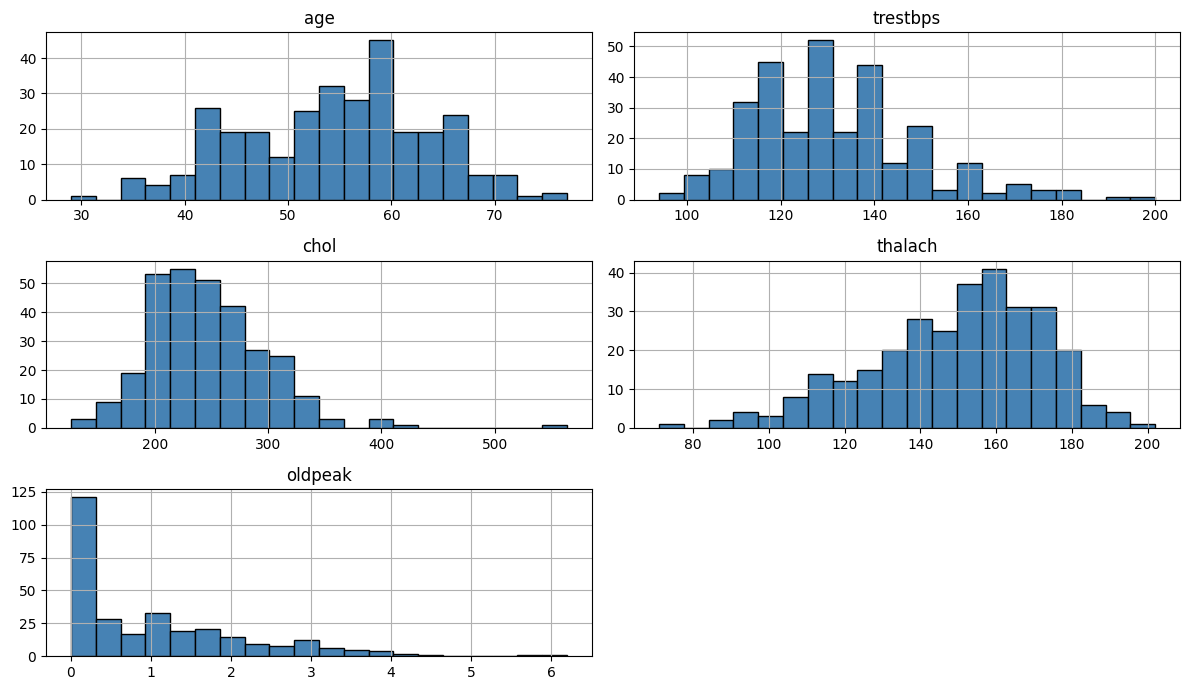

In [6]:
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
df[num_cols].hist(bins=20, figsize=(12, 7), color='steelblue', edgecolor='black')
plt.tight_layout()
plt.show()

`oldpeak` is skewed (many zeros). `chol` has a few big values (outliers > 400) but I kept them since they can be real.

## Correlation heatmap

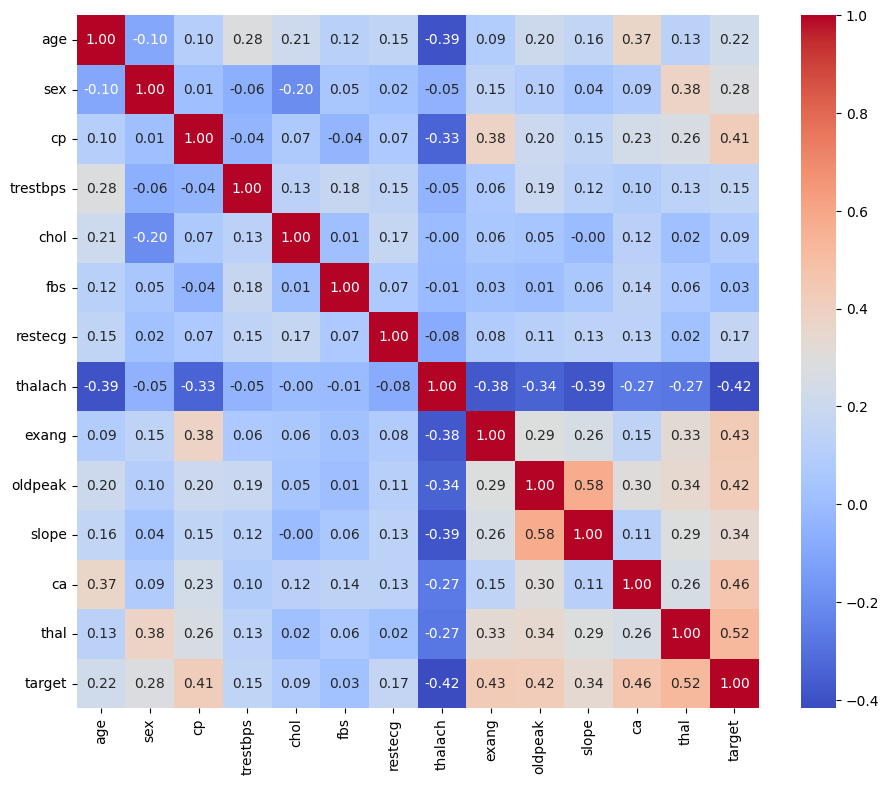

In [7]:
plt.figure(figsize=(11, 9))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [8]:
df.corr()['target'].drop('target').sort_values()

thalach    -0.417167
fbs         0.025264
chol        0.085164
trestbps    0.150825
restecg     0.169202
age         0.223120
sex         0.276816
slope       0.339213
cp          0.414446
oldpeak     0.424510
exang       0.431894
ca          0.460033
thal        0.522057
Name: target, dtype: float64

Strongest relations with target: `thal`, `ca`, `exang`, `oldpeak`, `cp` (positive) and `thalach` (negative - higher max heart rate means lower risk).

## A few more plots

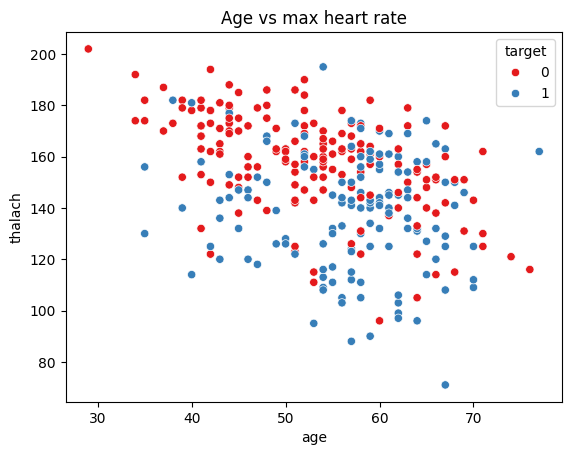

In [9]:
sns.scatterplot(x='age', y='thalach', hue='target', data=df, palette='Set1')
plt.title('Age vs max heart rate')
plt.show()

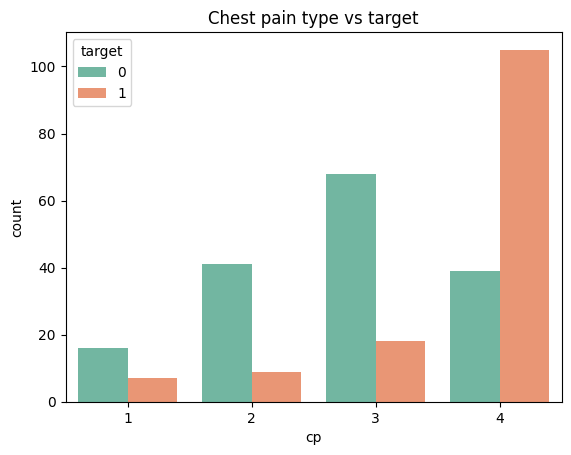

In [10]:
sns.countplot(x='cp', hue='target', data=df, palette='Set2')
plt.title('Chest pain type vs target')
plt.show()

Chest pain type 4 (asymptomatic) has many more disease cases, interesting.

## Decisions for modelling
- numeric columns -> StandardScaler (needed for Logistic Regression)
- `cp`, `restecg`, `slope`, `ca`, `thal` -> one hot encoding (they are categories, not real numbers)
- `sex`, `fbs`, `exang` already 0/1 -> keep as is
- these steps are in `src/preprocess.py` and used inside a sklearn Pipeline so the API uses the exact same preprocessing